<a href="https://colab.research.google.com/github/bahaali273/COMP9170-Hospital-Readmission/blob/bahaa-dev/notebooks/05_model_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Hospital Readmission Prediction — Model Comparison

**Course:** COMP 9170 — Data Science  
**Author:** Bahaa Al-Juboori

## 1. Model Comparison Methodology

### Objective
Compare traditional and advanced machine learning approaches for predicting 30-day hospital readmission.

### Models
1. Logistic Regression
2. Random Forest
3. XGBoost
4. Regularized MLP Neural Network
5. NVIDIA Kumo-Tabular (development analysis only)

### Evaluation Protocol
- Use the same processed training and test datasets for the four main models.
- Use a stratified 80/20 training-validation split with random_state=42.
- Select classification thresholds using validation data.
- Evaluate final model performance on the held-out test dataset.
- Compare PR-AUC, ROC-AUC, Precision, Recall, and F1-score.
- Report differences in model performance without claiming statistical significance.
- Keep Kumo-Tabular development-validation results separate from held-out test comparisons.

### Decisions
- PR-AUC is the primary metric due to class imbalance.
- ROC-AUC measures ranking discrimination.
- Precision, Recall, and F1 evaluate threshold-dependent classification.
- Results will be interpreted in the context of hospital readmission prediction.




## 2. Load and Consolidate Model Results

### Decisions
- Load traditional ML results from Jason's evaluation CSV.
- Retain only held-out test results for the main comparison.
- Include the regularized MLP's final test metrics.
- Keep NVIDIA Kumo-Tabular results separate because they were obtained on development-validation data.
- Compare models using the same evaluation metrics.


### Results
- Successfully consolidated held-out test results for four models.
- All results are reported for the binary 30-day readmission task.
- Regularized MLP achieved the highest reported PR-AUC (0.1579).
- Random Forest achieved the highest ROC-AUC (0.6477).
- Regularized MLP achieved the highest precision (0.1597).
- XGBoost achieved the highest recall (0.4598) and F1-score (0.2337).
- Model performance differences were relatively small.
- No statistical significance tests have been performed.
- These comparisons assume the models used identical held-out test records.
- NVIDIA Kumo-Tabular is excluded because its results were obtained on a different development-validation sample.



In [2]:

import pandas as pd

# Load Jason's baseline model results
baseline_df = pd.read_csv(
    "/content/baseline_models_metrics.csv"
)

# Keep only the final test results
test_baselines = baseline_df[
    baseline_df["Split"] == "test"
].copy()

# Add the regularized MLP final test results
mlp_result = pd.DataFrame([{
    "Model": "Regularized MLP",
    "Split": "test",
    "Threshold": 0.56,
    "PR-AUC": 0.1579,
    "ROC-AUC": 0.6416,
    "Precision": 0.1597,
    "Recall": 0.4072,
    "F1": 0.2294
}])

# Combine all four models
comparison_df = pd.concat(
    [test_baselines, mlp_result],
    ignore_index=True
)

# Sort by the primary evaluation metric
comparison_df = comparison_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("Final Held-Out Test Comparison:")
display(comparison_df.round(4))


Final Held-Out Test Comparison:


,Model,Split,Threshold,PR-AUC,ROC-AUC,Precision,Recall,F1
0,Regularized MLP,test,0.56,0.1579,0.6416,0.1597,0.4072,0.2294
1,Random Forest,test,0.33,0.1568,0.6477,0.1583,0.4064,0.2278
2,XGBoost,test,0.52,0.1567,0.6420,0.1566,0.4598,0.2337
3,Logistic Regression,test,0.54,0.1493,0.6354,0.1462,0.4494,0.2207



## 3. Model Performance Visualization

### Decisions
- Visualize PR-AUC, ROC-AUC, Precision, Recall, and F1-score.
- Use the consolidated held-out test metrics.
- Compare the four main classification models.
- Preserve the original evaluation results without modification.
- Export publication-ready figures for the final report.


### Results
- Successfully generated a grouped bar chart comparing four models.
- Models: Logistic Regression, Random Forest, XGBoost, and Regularized MLP.
- Metrics: PR-AUC, ROC-AUC, Precision, Recall, and F1-score.
- Regularized MLP achieved the highest reported PR-AUC (0.1579).
- Random Forest achieved the highest ROC-AUC (0.6477).
- XGBoost achieved the highest recall (0.4598) and F1-score (0.2337).
- Performance differences across models were relatively small.
- Saved the visualization as `results/model_comparison_metrics.png` at 300 DPI.
- Kumo-Tabular was excluded because its results were obtained from a separate development-validation sample.



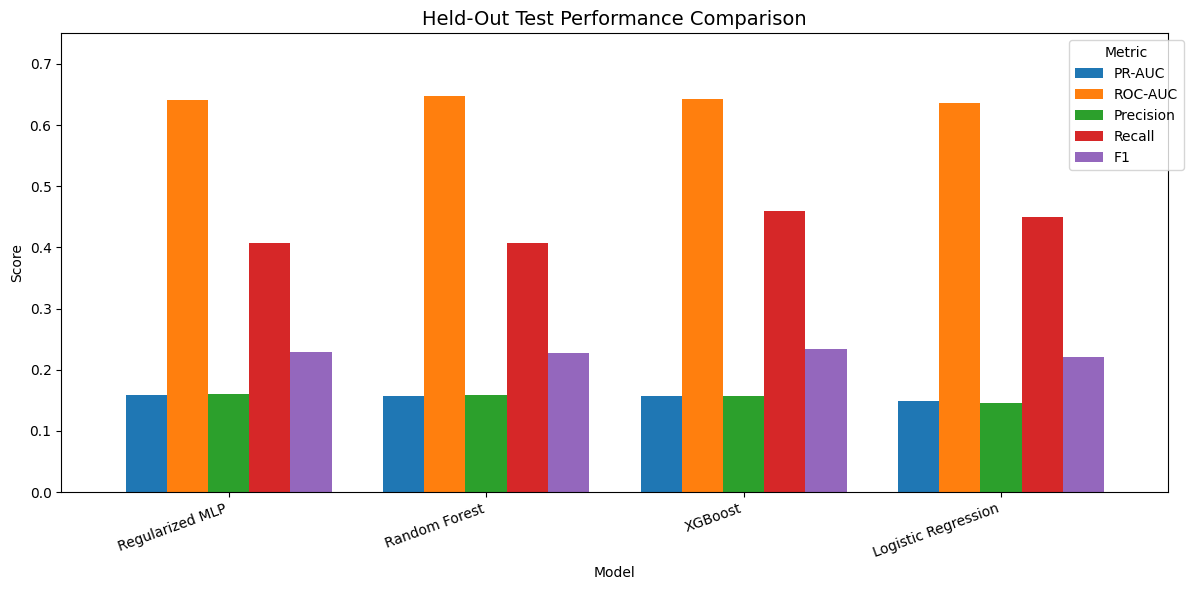

Saved: results/model_comparison_metrics.png


In [3]:

import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("results", exist_ok=True)

metrics = [
    "PR-AUC",
    "ROC-AUC",
    "Precision",
    "Recall",
    "F1"
]

plot_df = comparison_df.set_index("Model")[metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title(
    "Held-Out Test Performance Comparison",
    fontsize=14
)
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 0.75)

plt.xticks(rotation=20, ha="right")
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1))
plt.tight_layout()

plt.savefig(
    "results/model_comparison_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/model_comparison_metrics.png")


## 4. Primary Metric Comparison — PR-AUC

### Decisions
- Focus on Average Precision (PR-AUC) as the primary metric.
- Compare all four models on the held-out test dataset.
- Include the approximate random-classifier baseline based on class prevalence.
- Display exact metric values to make small differences visible.
- Avoid interpreting small observed differences as statistically significant.


### Results
- Successfully generated a focused PR-AUC comparison chart.
- Regularized MLP: 0.1579.
- Random Forest: 0.1568.
- XGBoost: 0.1567.
- Logistic Regression: 0.1493.
- Approximate random-ranking baseline: 0.0897.
- All four models achieved PR-AUC values above the positive-class prevalence baseline.
- Regularized MLP achieved the highest observed PR-AUC.
- The performance differences were small and have not been tested for statistical significance.
- Saved the chart as `results/model_comparison_prauc.png` at 300 DPI.


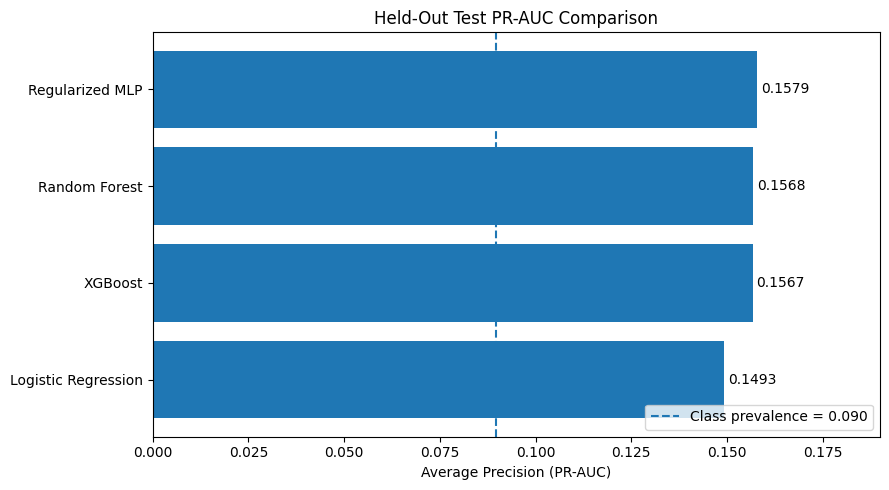

Saved: results/model_comparison_prauc.png


In [4]:

import matplotlib.pyplot as plt

prauc_df = comparison_df.sort_values(
    "PR-AUC", ascending=True
)

# Approximate positive prevalence in the test set
random_baseline = 1255 / 13994

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.barh(
    prauc_df["Model"],
    prauc_df["PR-AUC"]
)

ax.axvline(
    random_baseline,
    linestyle="--",
    linewidth=1.5,
    label=f"Class prevalence = {random_baseline:.3f}"
)

for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

ax.set_xlim(0, 0.19)
ax.set_xlabel("Average Precision (PR-AUC)")
ax.set_title("Held-Out Test PR-AUC Comparison")
ax.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    "results/model_comparison_prauc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/model_comparison_prauc.png")




## 5. Results Interpretation and Discussion

### Main Findings

Four supervised learning models were compared for predicting
30-day hospital readmission using the held-out test dataset.

The regularized MLP achieved the highest observed PR-AUC
(0.1579), followed closely by Random Forest (0.1568),
XGBoost (0.1567), and Logistic Regression (0.1493).

Random Forest achieved the highest ROC-AUC (0.6477),
while XGBoost achieved the highest F1-score (0.2337)
and recall (0.4598).

The relatively small differences in predictive performance
suggest that the more complex models did not demonstrate a
substantial advantage over the simpler baselines in these
experiments.

### Class Imbalance

Approximately 9% of patients experienced readmission within
30 days. Therefore, PR-AUC was selected as the primary
evaluation metric because it summarizes precision-recall
performance across classification thresholds.

Although all four models exceeded the approximate
random-ranking baseline, the PR-AUC values indicate
considerable difficulty in identifying patients who
will be readmitted.

### Limitations

- The models were evaluated using a historical hospital dataset.
- The dataset contains a substantial class imbalance.
- Small differences between model scores do not establish
  statistically significant performance differences.
- Threshold-dependent metrics are affected by the selected
  classification threshold.
- External validation on a different hospital dataset
  has not been performed.
- NVIDIA Kumo-Tabular was evaluated separately on development
  samples and is not included in the held-out test ranking.

### Conclusion

The regularized MLP achieved the highest observed PR-AUC,
but no single model consistently outperformed the others
across all evaluation metrics.

The findings emphasize the importance of careful evaluation,
class imbalance handling, and interpretability when applying
machine learning to hospital readmission prediction.
